# Generative AI Use and Student Outcomes

**Business question:** how does students' use of generative AI (ChatGPT-style tools) relate to their grades, study habits, knowledge retention and well-being?

**Research questions**
1. Does AI improve students' GPA?
2. Are students becoming overly dependent on AI?
3. Does increased AI usage reduce traditional study hours?
4. Does AI affect knowledge retention?
5. What factors contribute most to burnout?
6. Which student groups rely on AI the most?

**Dataset:** 50,000 students and 16 columns, with no missing values. It records each student's major, year of study, GPA before and after the semester, weekly AI hours, main use of AI, prompt-writing skill, number of AI tools used, whether they pay for a subscription, traditional study hours, perceived AI dependency (1-10), the institution's AI policy, exam anxiety (1-10), a skill retention score (0-100) and burnout risk (Low, Medium, High). The dataset does not say how the data was collected, so the results describe patterns in this dataset only.

**Tools:** Python (pandas, matplotlib).

**Contents:** 1. Setup and loading, 2. Data audit (including distributions and outliers), 3. Who uses AI the most, 4. Preparing the analysis columns, 5. Does AI improve GPA, 6. AI dependency, 7. Traditional study hours, 8. Knowledge retention, 9. Burnout, 10. Correlation overview, 11. Findings, 12. Recommendations, 13. Limitations

## 1. Setup and loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv(r"C:\Users\HomePC\Downloads\ai_student_impact_dataset (1).csv")

## 2. Data audit

The first rows, the values of the main category columns, and the size and data types of the table are checked before any analysis.

In [4]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


### Checking the categories

The unique values of each category column are listed to check for spelling variants or inconsistent labels.

In [5]:
df['Institutional_Policy'].unique()

array(['Allowed_With_Citation', 'Strict_Ban', 'Actively_Encouraged'],
      dtype=object)

In [6]:
df['Major_Category'].unique()

array(['Humanities', 'Medical', 'Business', 'STEM', 'Arts'], dtype=object)

The `Major_Category` column shows the department or course category of each student: Humanities, Medical, Business, STEM and Arts.

In [7]:

df['Burnout_Risk_Level'].unique()

array(['High', 'Low', 'Medium'], dtype=object)

In [8]:
df['Year_of_Study'].unique()

array(['Senior', 'Junior', 'Freshman', 'Sophomore', 'Graduate'],
      dtype=object)

In [9]:
df['Primary_Use_Case'].unique()

array(['Copywriting/Drafting', 'Ideation', 'Summarizing_Reading',
       'Debugging/Troubleshooting', 'Direct_Answer_Generation'],
      dtype=object)

In [10]:
df['Prompt_Engineering_Skill'].unique()

array(['Beginner', 'Advanced', 'Intermediate'], dtype=object)

In [11]:
# proper
df['Major_Category'] = df['Major_Category'].str.title()

In [12]:
# str.title() changed 'STEM' to 'Stem', so it is changed back
df['Major_Category'] = df['Major_Category'].replace({'Stem': 'STEM'})

In [13]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           500

In [15]:
df.shape

(50000, 16)

In [16]:
df.isnull().sum()

Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

**What the audit shows**
- The table has 50,000 students and 16 columns, with no missing values in any column.
- Text columns have clean, consistent categories, so very little cleaning was needed. The one fix is `Major_Category`: converting to title case turned `STEM` into `Stem`, so it is changed back to `STEM`.

### Distributions and outliers

Histograms show how each main numeric column is spread, and the IQR rule flags unusual values (more than 1.5 times the interquartile range beyond the middle 50% of the data). These checks are done before the analysis so the later results can be read with the shape of the data in mind.

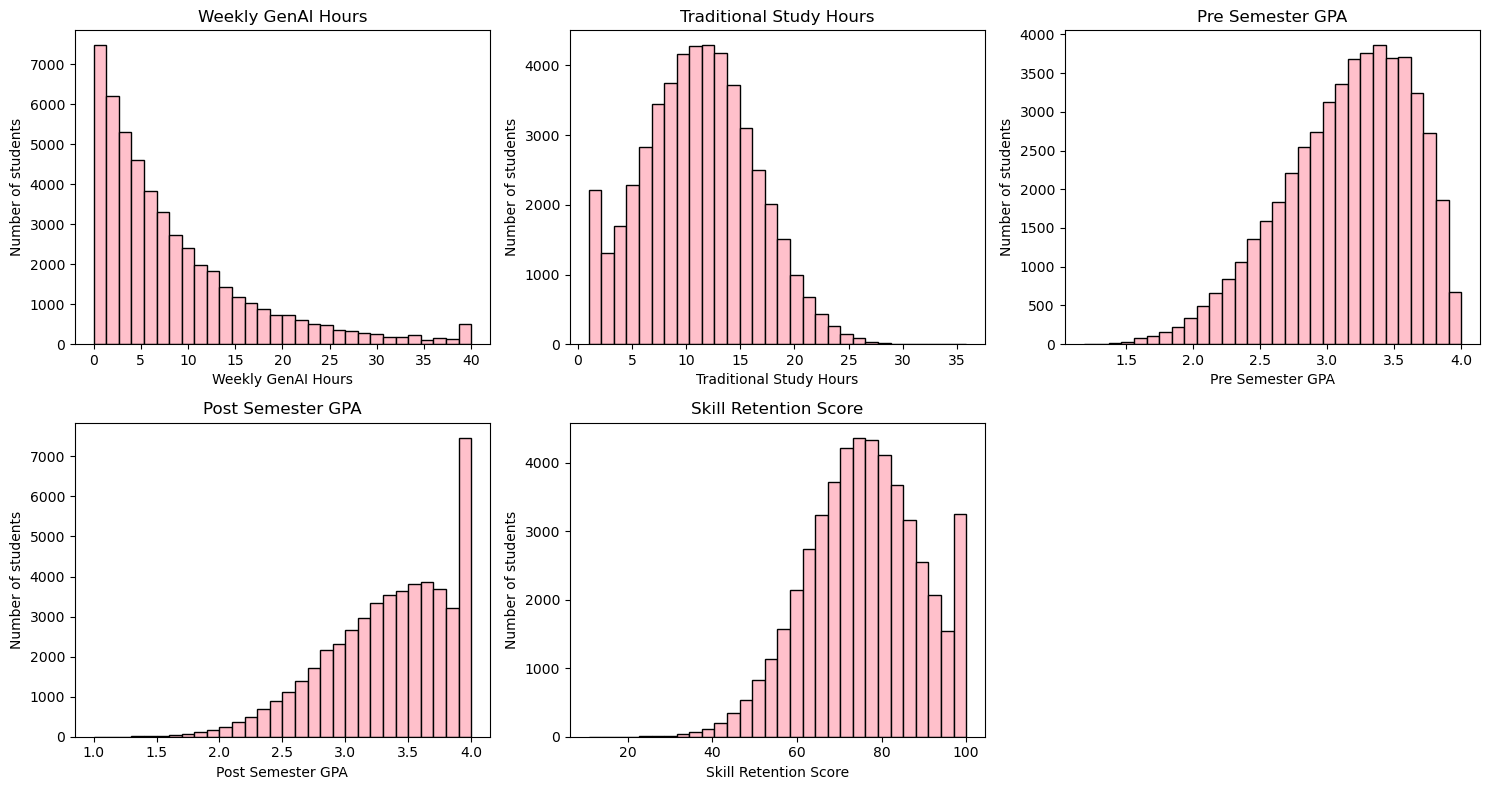

In [17]:
# Histograms of the main numeric columns
hist_cols = ['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Pre_Semester_GPA', 'Post_Semester_GPA', 'Skill_Retention_Score']

plt.figure(figsize = (15,8))
for i, col in enumerate(hist_cols):
    plt.subplot(2, 3, i + 1)
    plt.hist(df[col], bins = 30, color = 'pink', edgecolor = 'black')
    plt.title(col.replace('_', ' '))
    plt.xlabel(col.replace('_', ' '))
    plt.ylabel('Number of students')
plt.tight_layout()
plt.show()

In [18]:
# Outlier check with the IQR rule: a value is an outlier if it is more than 1.5 x IQR below Q1 or above Q3
rows = []
for col in hist_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append([col, df[col].median(), df[col].mean(), df[col].max(), lower, upper, n_out, n_out / len(df) * 100])

outlier_table = pd.DataFrame(rows, columns = ['Column', 'Median', 'Mean', 'Max', 'Lower_Limit', 'Upper_Limit', 'Outliers', 'Outliers_%']).round(2)
outlier_table

,Column,Median,Mean,Max,Lower_Limit,Upper_Limit,Outliers,Outliers_%
0,Weekly_GenAI_Hours,5.80,8.43,40.00,-11.60,25.72,2583,5.17
1,Traditional_Study_Hours,11.18,11.21,35.86,-3.17,25.44,161,0.32
2,Pre_Semester_GPA,3.21,3.15,4.00,1.80,4.55,328,0.66
3,Post_Semester_GPA,3.42,3.35,4.00,1.94,4.84,346,0.69
4,Skill_Retention_Score,76.00,75.80,100.00,39.26,112.74,216,0.43


In [19]:
# Values piled up at the limits of each column
print("Students with exactly 40 AI hours:         ", (df['Weekly_GenAI_Hours'] == 40).sum())
print("Students with exactly 1 study hour:        ", (df['Traditional_Study_Hours'] == 1).sum())
print("Students with a final GPA of exactly 4.0:  ", (df['Post_Semester_GPA'] == 4.0).sum())
print("Students with a retention score of 100:    ", (df['Skill_Retention_Score'] == 100).sum())

Students with exactly 40 AI hours:          448
Students with exactly 1 study hour:         1269
Students with a final GPA of exactly 4.0:   4804
Students with a retention score of 100:     2146


**What the distributions show.** Weekly AI hours are strongly right-skewed: most students use AI a little (median 5.8 hours a week), but a tail of heavy users pulls the average up to 8.4. GPA and retention scores are bunched toward the high end.

**Values piled up at the limits.** 448 students (0.9%) report exactly 40 AI hours, 1,269 (2.5%) exactly 1 study hour, 4,804 (9.6%) a final GPA of exactly 4.0 and 2,146 (4.3%) a retention score of 100. The data appears to be capped at these limits, so differences among students at the top may be hidden.

**Outliers.** By the IQR rule, 2,583 students (5.2%) use AI for more than about 25.7 hours a week and 161 study for more than about 25.4 hours. GPA and retention have a few hundred low-end outliers (under 1% of students). These are plausible values (heavy users, struggling students) rather than errors, and heavy users are central to the questions asked, so nothing was removed.

## 3. Who uses AI the most?  (Research question 6)

Average weekly hours of AI use are compared across student groups.

In [20]:
major_ai = df.groupby("Major_Category")["Weekly_GenAI_Hours"].mean().sort_values(ascending=False)

major_ai

Major_Category
STEM          10.488609
Business       8.275898
Medical        7.546728
Arts           7.271702
Humanities     6.770144
Name: Weekly_GenAI_Hours, dtype: float64

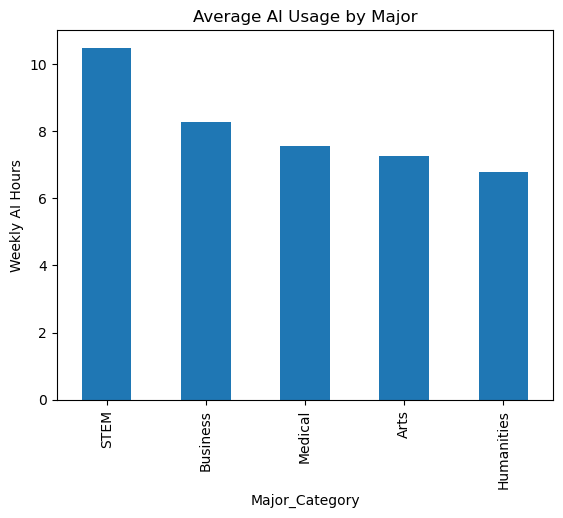

In [21]:
major_ai.plot(kind="bar")

plt.title("Average AI Usage by Major")
plt.ylabel("Weekly AI Hours")
plt.show()

**By major.** STEM students use AI the most (about 10.5 hours a week), followed by Business (8.3), Medical (7.5) and Arts (7.3). Humanities students use it the least (6.8 hours).

In [22]:
year_ai = df.groupby("Year_of_Study")["Weekly_GenAI_Hours"].mean().sort_values(ascending=False)

print(year_ai)

Year_of_Study
Senior       8.459251
Freshman     8.446962
Sophomore    8.446249
Graduate     8.406052
Junior       8.376325
Name: Weekly_GenAI_Hours, dtype: float64


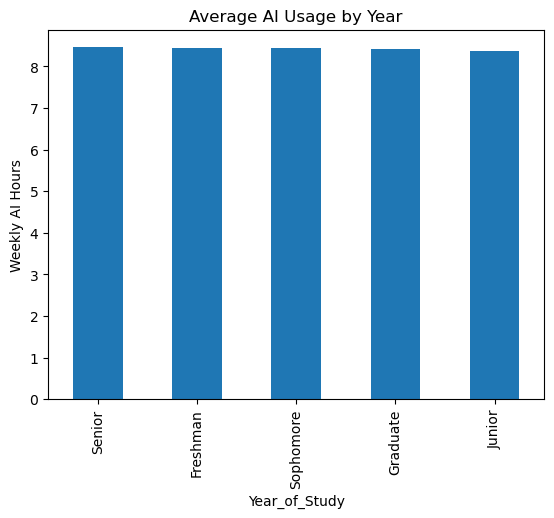

In [23]:
year_ai.plot(kind="bar")

plt.title("Average AI Usage by Year")
plt.ylabel("Weekly AI Hours")
plt.show()


**By year of study.** Usage is almost identical in every year (between about 8.4 and 8.5 hours a week), so year of study makes little difference.

In [24]:
# Average weekly AI hours for other student groups
for col in ['Paid_Subscription', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy']:
    print(df.groupby(col)['Weekly_GenAI_Hours'].mean().sort_values(ascending = False).round(2))
    print()

Paid_Subscription
True     10.33
False     7.03
Name: Weekly_GenAI_Hours, dtype: float64

Primary_Use_Case
Debugging/Troubleshooting    9.40
Direct_Answer_Generation     8.46
Ideation                     8.40
Summarizing_Reading          8.17
Copywriting/Drafting         7.63
Name: Weekly_GenAI_Hours, dtype: float64

Prompt_Engineering_Skill
Advanced        8.69
Intermediate    8.37
Beginner        8.29
Name: Weekly_GenAI_Hours, dtype: float64

Institutional_Policy
Actively_Encouraged      8.48
Allowed_With_Citation    8.42
Strict_Ban               8.37
Name: Weekly_GenAI_Hours, dtype: float64



**By other groups.**
- **Paid subscription:** students who pay for an AI subscription use it far more (about 10.3 hours a week) than those who do not (about 7.0).
- **Main use:** students who mainly use AI for debugging and troubleshooting use it the most (about 9.4 hours), and those using it for copywriting and drafting use it the least (about 7.6).
- **Prompt skill:** usage is similar across skill levels (about 8.3 to 8.7 hours).
- **Institutional policy:** reported usage is almost the same under every policy (about 8.4 to 8.5 hours), including where AI is strictly banned.

## 4. Preparing the analysis columns

Two columns are created to answer the questions below:
- `GPA_Change`: GPA after the semester minus GPA before it (a positive number means the student's GPA went up).
- `AI_Use_Band`: students grouped by weekly AI hours (0-5, 5-10, 10-20 and 20+ hours), so groups of light and heavy users can be compared.

In [25]:
# GPA change over the semester (positive = GPA went up)
df['GPA_Change'] = df['Post_Semester_GPA'] - df['Pre_Semester_GPA']

# Group students by weekly AI hours
df['AI_Use_Band'] = pd.cut(df['Weekly_GenAI_Hours'],
                           bins = [0, 5, 10, 20, 100],
                           labels = ['0-5 hrs', '5-10 hrs', '10-20 hrs', '20+ hrs'],
                           include_lowest = True)

df['AI_Use_Band'].value_counts().sort_index()

AI_Use_Band
0-5 hrs      22592
5-10 hrs     12173
10-20 hrs    10229
20+ hrs       5006
Name: count, dtype: int64

Most students are light users: 22,592 use AI for 5 hours a week or less, while 5,006 students (10%) use it for more than 20 hours a week.

## 5. Does AI improve students' GPA?  (Research question 1)

In [26]:
# Average GPA before and after the semester, and the average change
print(df[['Pre_Semester_GPA', 'Post_Semester_GPA', 'GPA_Change']].mean().round(3))
print()
print("Share of students whose GPA went up:", round((df['GPA_Change'] > 0).mean() * 100, 1), "%")

Pre_Semester_GPA     3.146
Post_Semester_GPA    3.349
GPA_Change           0.203
dtype: float64

Share of students whose GPA went up: 87.5 %


In [27]:
# GPA change and share of students who improved, for each AI use band
gpa_by_use = df.groupby('AI_Use_Band', observed = True).agg(
    Students = ('GPA_Change', 'size'),
    Avg_GPA_Change = ('GPA_Change', 'mean'),
    Share_Improved_pct = ('GPA_Change', lambda x: (x > 0).mean() * 100)).round(3)
gpa_by_use

,Students,Avg_GPA_Change,Share_Improved_pct
AI_Use_Band,,,
0-5 hrs,22592,0.195,87.071
5-10 hrs,12173,0.227,90.996
10-20 hrs,10229,0.216,88.308
20+ hrs,5006,0.156,79.465


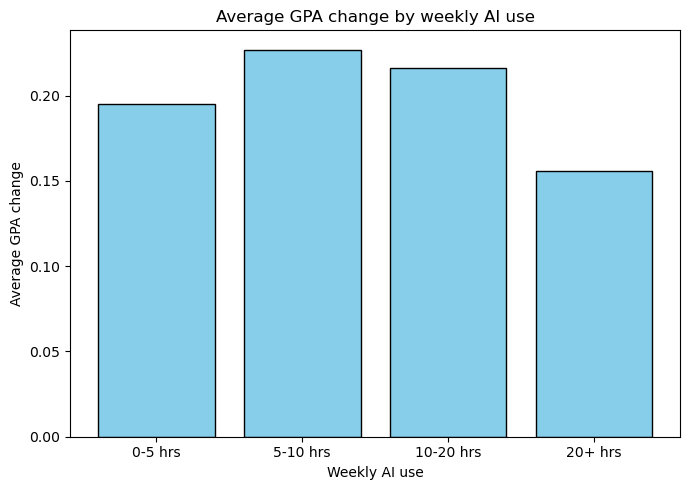

In [28]:
plt.figure(figsize = (7,5))
plt.bar(gpa_by_use.index, gpa_by_use['Avg_GPA_Change'], color = 'skyblue', edgecolor = 'black')
plt.title('Average GPA change by weekly AI use')
plt.ylabel('Average GPA change')
plt.xlabel('Weekly AI use')
plt.tight_layout()
plt.show()

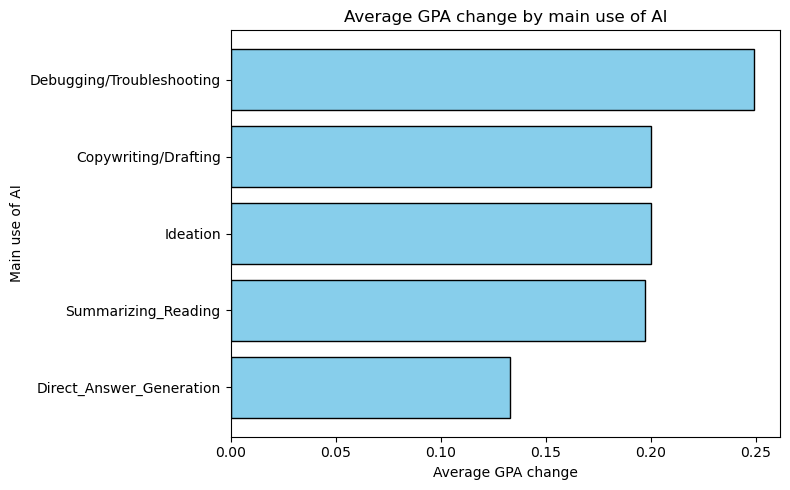

Primary_Use_Case
Direct_Answer_Generation     0.133
Summarizing_Reading          0.197
Ideation                     0.200
Copywriting/Drafting         0.200
Debugging/Troubleshooting    0.249
Name: GPA_Change, dtype: float64

In [29]:
# Average GPA change for each main use of AI
gpa_by_case = df.groupby('Primary_Use_Case')['GPA_Change'].mean().sort_values().round(3)

plt.figure(figsize = (8,5))
plt.barh(gpa_by_case.index, gpa_by_case.values, color = 'skyblue', edgecolor = 'black')
plt.title('Average GPA change by main use of AI')
plt.xlabel('Average GPA change')
plt.ylabel('Main use of AI')
plt.tight_layout()
plt.show()

gpa_by_case

**GPA overall.** Average GPA rose from about 3.15 to 3.35 over the semester (an average gain of 0.20), and about 87% of students improved.

**GPA by AI use.** More AI use does not mean bigger gains. Students using AI 5-10 hours a week gained the most (+0.23), students using it for 10-20 hours gained +0.22, and light users (0-5 hours) gained +0.19. Heavy users (20+ hours) gained the least (+0.16), and a smaller share of them improved (79%, compared with 87% to 91% in the other groups).

**GPA by main use.** How students use AI matters. Debugging and troubleshooting is linked to the biggest gains (+0.25), while generating direct answers is linked to the smallest (+0.13).

## 6. Are students becoming overly dependent on AI?  (Research question 2)

`Perceived_AI_Dependency` is a 1-10 score. It is compared across the AI use bands, and the share of students with a high score (7 or more) is calculated.

In [30]:
# Average dependency score, and share of students with a high score (7 or more), for each use band
df['High_Dependency'] = df['Perceived_AI_Dependency'] >= 7

dependency_by_use = df.groupby('AI_Use_Band', observed = True).agg(
    Avg_Dependency = ('Perceived_AI_Dependency', 'mean'),
    High_Dependency_pct = ('High_Dependency', lambda x: x.mean() * 100)).round(2)
dependency_by_use

,Avg_Dependency,High_Dependency_pct
AI_Use_Band,,
0-5 hrs,2.63,0.04
5-10 hrs,3.30,0.57
10-20 hrs,4.30,6.88
20+ hrs,6.37,47.20


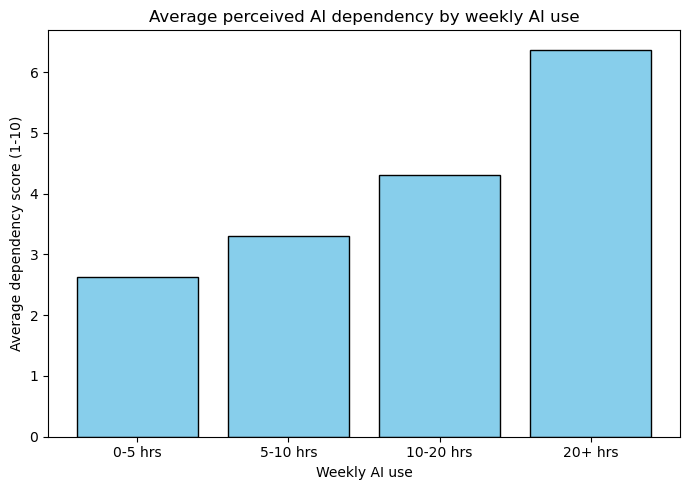

In [31]:
plt.figure(figsize = (7,5))
plt.bar(dependency_by_use.index, dependency_by_use['Avg_Dependency'], color = 'skyblue', edgecolor = 'black')
plt.title('Average perceived AI dependency by weekly AI use')
plt.ylabel('Average dependency score (1-10)')
plt.xlabel('Weekly AI use')
plt.tight_layout()
plt.show()

**Dependency rises sharply with usage.** The average score goes from 2.6 (0-5 hours) to 3.3, 4.3 and 6.4 for the heaviest users (20+ hours). Almost no student using AI 10 hours a week or less rates their dependency as high, but 47% of the 20+ hour group do. The link between hours and dependency is strong (correlation 0.67, see section 10).

## 7. Does increased AI usage reduce traditional study hours?  (Research question 3)

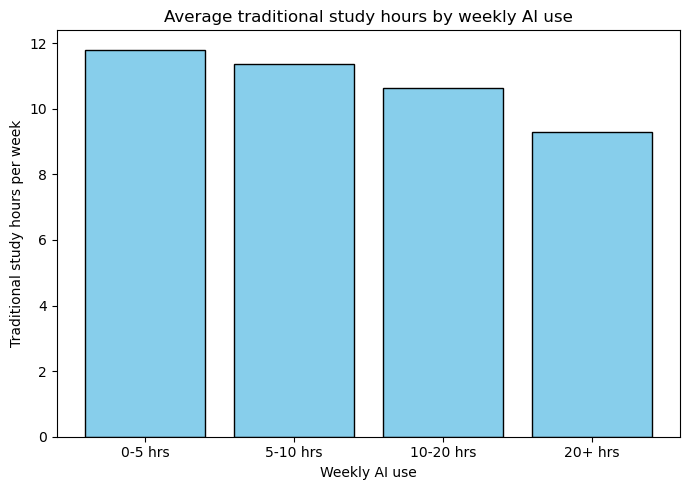

AI_Use_Band
0-5 hrs      11.80
5-10 hrs     11.37
10-20 hrs    10.63
20+ hrs       9.30
Name: Traditional_Study_Hours, dtype: float64

In [32]:
# Average traditional study hours for each AI use band
study_by_use = df.groupby('AI_Use_Band', observed = True)['Traditional_Study_Hours'].mean().round(2)

plt.figure(figsize = (7,5))
plt.bar(study_by_use.index, study_by_use.values, color = 'skyblue', edgecolor = 'black')
plt.title('Average traditional study hours by weekly AI use')
plt.ylabel('Traditional study hours per week')
plt.xlabel('Weekly AI use')
plt.tight_layout()
plt.show()

study_by_use

In [33]:
# GPA change for students grouped by traditional study hours
df['Study_Band'] = pd.cut(df['Traditional_Study_Hours'],
                          bins = [0, 5, 10, 15, 100],
                          labels = ['0-5 hrs', '5-10 hrs', '10-15 hrs', '15+ hrs'],
                          include_lowest = True)

gpa_by_study = df.groupby('Study_Band', observed = True).agg(
    Students = ('GPA_Change', 'size'),
    Avg_GPA_Change = ('GPA_Change', 'mean')).round(3)
gpa_by_study

,Students,Avg_GPA_Change
Study_Band,,
0-5 hrs,6185,0.086
5-10 hrs,14451,0.156
10-15 hrs,17695,0.222
15+ hrs,11669,0.295


**Study hours fall as AI use rises, but only modestly.** Light users study about 11.8 hours a week in the traditional way, and the heaviest users about 9.3 hours (correlation -0.16, a weak link).

**Traditional study matters more for GPA than AI use does.** Students who study 0-5 hours gain only +0.09 GPA points, rising to +0.30 for those studying 15 or more hours. The link between study hours and GPA change (correlation 0.38) is much stronger than the link between AI hours and GPA change (-0.05).

## 8. Does AI affect knowledge retention?  (Research question 4)

`Skill_Retention_Score` (0-100) is compared by AI use, prompt-writing skill and the number of AI tools used.

In [34]:
# Average retention score by AI use band, prompt skill and number of tools used
print(df.groupby('AI_Use_Band', observed = True)['Skill_Retention_Score'].mean().round(1))
print()
print(df.groupby('Prompt_Engineering_Skill')['Skill_Retention_Score'].mean().sort_values(ascending = False).round(1))
print()
print(df.groupby('Tool_Diversity')['Skill_Retention_Score'].mean().round(1))

AI_Use_Band
0-5 hrs      76.0
5-10 hrs     77.1
10-20 hrs    76.6
20+ hrs      70.3
Name: Skill_Retention_Score, dtype: float64

Prompt_Engineering_Skill
Advanced        82.1
Intermediate    75.8
Beginner        71.1
Name: Skill_Retention_Score, dtype: float64

Tool_Diversity
1    72.6
2    73.0
3    76.4
4    79.4
5    79.8
Name: Skill_Retention_Score, dtype: float64


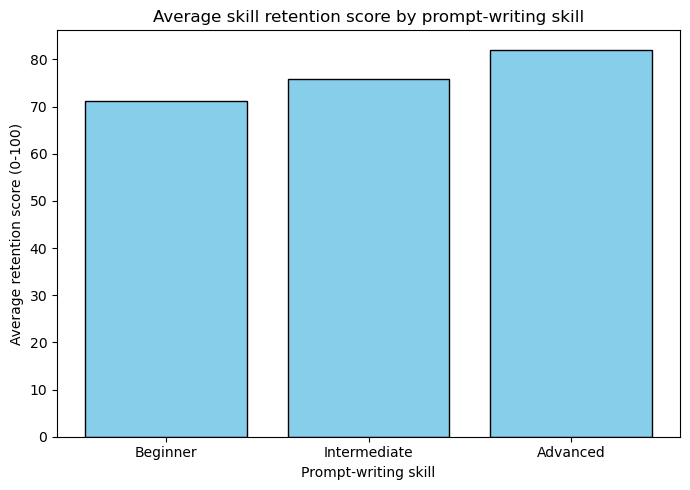

In [35]:
retention_by_skill = df.groupby('Prompt_Engineering_Skill')['Skill_Retention_Score'].mean().reindex(['Beginner', 'Intermediate', 'Advanced'])

plt.figure(figsize = (7,5))
plt.bar(retention_by_skill.index, retention_by_skill.values, color = 'skyblue', edgecolor = 'black')
plt.title('Average skill retention score by prompt-writing skill')
plt.ylabel('Average retention score (0-100)')
plt.xlabel('Prompt-writing skill')
plt.tight_layout()
plt.show()

**Heavy use is linked to lower retention.** The average retention score is about 76 to 77 for students using AI up to 20 hours a week, but drops to about 70 for the heaviest users (20+ hours).

**Skill matters.** Advanced prompt writers score about 82, compared with about 76 for intermediate and 71 for beginners, an 11-point gap. Using more AI tools also helps: the score rises from about 73 for students using one tool to about 80 for those using five.

## 9. What factors contribute most to burnout?  (Research question 5)

Burnout risk is Low, Medium or High. First the burnout mix is compared across AI use bands, then the share of students at **High** risk is compared across other factors.

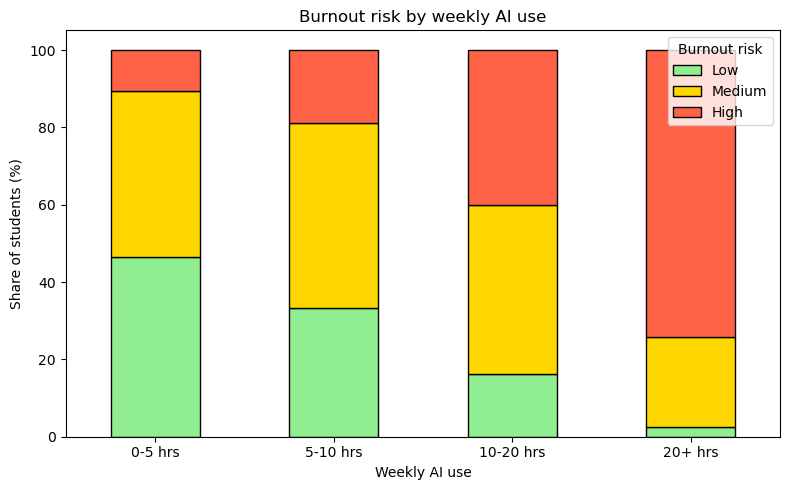

Burnout_Risk_Level,Low,Medium,High
AI_Use_Band,,,
0-5 hrs,46.6,42.9,10.5
5-10 hrs,33.2,47.9,19.0
10-20 hrs,16.3,43.7,40.0
20+ hrs,2.5,23.2,74.3


In [36]:
# Share (%) of students at each burnout level, within each AI use band
burnout_mix = pd.crosstab(df['AI_Use_Band'], df['Burnout_Risk_Level'], normalize = 'index') * 100
burnout_mix = burnout_mix[['Low', 'Medium', 'High']].round(1)

burnout_mix.plot(kind = 'bar', stacked = True, figsize = (8,5), edgecolor = 'black', color = ['lightgreen', 'gold', 'tomato'])
plt.title('Burnout risk by weekly AI use')
plt.ylabel('Share of students (%)')
plt.xlabel('Weekly AI use')
plt.xticks(rotation = 0)
plt.legend(title = 'Burnout risk')
plt.tight_layout()
plt.show()

burnout_mix

In [37]:
# Share (%) of students at High burnout risk, overall and for other factors
df['High_Burnout'] = df['Burnout_Risk_Level'] == 'High'
print("Overall:", round(df['High_Burnout'].mean() * 100, 1), "%")
#print()

for col in ['Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Study_Band', 'Major_Category', 'Paid_Subscription', 'Institutional_Policy']:
    print((df.groupby(col, observed = True)['High_Burnout'].mean() * 100).round(1))
    #print()

Overall: 25.0 %
Perceived_AI_Dependency
1      9.9
2     13.4
3     18.3
4     24.1
5     32.9
6     48.5
7     66.4
8     79.5
9     86.2
10    94.7
Name: High_Burnout, dtype: float64
Anxiety_Level_During_Exams
1     17.7
2     18.8
3     20.8
4     22.0
5     26.2
6     26.5
7     33.0
8     39.1
9     49.0
10    70.2
Name: High_Burnout, dtype: float64
Study_Band
0-5 hrs      34.8
5-10 hrs     28.4
10-15 hrs    23.3
15+ hrs      18.1
Name: High_Burnout, dtype: float64
Major_Category
Arts          22.7
Business      24.3
Humanities    20.7
Medical       23.2
STEM          30.0
Name: High_Burnout, dtype: float64
Paid_Subscription
False    21.1
True     30.2
Name: High_Burnout, dtype: float64
Institutional_Policy
Actively_Encouraged      23.8
Allowed_With_Citation    23.8
Strict_Ban               29.8
Name: High_Burnout, dtype: float64


**Heavy AI use is the clearest factor.** About 25% of all students are at high burnout risk, but the share rises from 10.5% (0-5 hours of AI a week) to 19.0%, 40.0% and 74.3% for the heaviest users (20+ hours).

**Other factors that go with burnout**
- **Dependency:** the share at high risk rises from about 10% at dependency level 1 to about 95% at level 10.
- **Exam anxiety:** it rises from about 18% at anxiety level 1 to about 70% at level 10.
- **Study hours:** students who study 0-5 hours a week are at high risk more often (about 35%) than those who study 15 or more hours (about 18%).
- **Major:** STEM students have the highest share (30%), which fits with them being the heaviest AI users.
- **Paid subscription:** 30% of subscribers are at high risk, compared with 21% of non-subscribers, again matching their higher usage.
- **Institutional policy:** students under a strict AI ban are slightly more often at high risk (about 30%) than under the other policies (about 24%).

Prompt-writing skill makes no difference to burnout (about 25% at every level).

## 10. Correlation overview

A correlation shows how strongly two numbers move together: 1 means they rise together perfectly, -1 means one rises as the other falls, and 0 means no link.

In [38]:
numeric_cols = ['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Perceived_AI_Dependency',
                'Anxiety_Level_During_Exams', 'GPA_Change', 'Skill_Retention_Score']
df[numeric_cols].corr().round(2)

,Weekly_GenAI_Hours,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,GPA_Change,Skill_Retention_Score
Weekly_GenAI_Hours,1.00,-0.16,0.67,0.27,-0.05,-0.12
Traditional_Study_Hours,-0.16,1.00,-0.10,-0.04,0.38,0.15
Perceived_AI_Dependency,0.67,-0.10,1.00,0.31,-0.04,-0.08
Anxiety_Level_During_Exams,0.27,-0.04,0.31,1.00,-0.04,-0.04
GPA_Change,-0.05,0.38,-0.04,-0.04,1.00,0.20
Skill_Retention_Score,-0.12,0.15,-0.08,-0.04,0.20,1.00


The strongest links are between weekly AI hours and perceived dependency (0.67), traditional study hours and GPA change (0.38), AI hours and exam anxiety (0.27), and skill retention and GPA change (0.20). The link between AI hours and GPA change is close to zero (-0.05).

## 11. Findings: answers to the research questions

**1. Does AI improve students' GPA?** GPA rose by 0.20 on average and 87% of students improved, but heavier AI use does not bring bigger gains. Moderate users (5-10 hours a week) gained the most (+0.23) while the heaviest users (20+ hours) gained the least (+0.16). How AI is used matters: debugging is linked to the biggest gains (+0.25) and direct answer generation to the smallest (+0.13).

**2. Are students becoming overly dependent on AI?** Heavy users are. Average dependency rises from 2.6 to 6.4 across the use bands, and 47% of students using AI more than 20 hours a week rate their dependency as high (7 or more).

**3. Does increased AI usage reduce traditional study hours?** Slightly. Heavy users study about 9.3 hours a week against 11.8 for light users. Traditional study hours are far more strongly linked to GPA gains than AI hours.

**4. Does AI affect knowledge retention?** Heavy use is linked to lower retention (about 70 against 76 to 77). Prompt-writing skill and using more AI tools are linked to higher retention (advanced 82, beginner 71).

**5. What factors contribute most to burnout?** Weekly AI hours stand out: 74% of students using AI more than 20 hours a week are at high risk, against 10.5% of light users. High dependency and exam anxiety also go with high burnout.

**6. Which student groups rely on AI the most?** STEM students (about 10.5 hours a week), paid subscribers (10.3 hours) and students who mainly use AI for debugging (9.4 hours). Year of study and institutional policy make almost no difference to usage.

## 12. Recommendations

1. **Encourage moderate use.** Students using AI 5-10 hours a week gained the most in GPA, so moderate use looks like a sensible target.
2. **Support students who use AI more than 20 hours a week.** This group has the lowest GPA gains and retention, the highest dependency and the highest burnout risk (74%). Counselling, usage guidance or study-skills support could help.
3. **Promote active uses of AI.** Debugging and ideation are linked to better results than generating direct answers, so teach students to use AI to work through problems rather than to get answers.
4. **Offer prompt-writing training.** Advanced prompt writers retain about 11 points more than beginners.
5. **Protect traditional study time.** It has the strongest link to GPA improvement.
6. **Watch STEM students and paid subscribers.** They use AI the most and show higher burnout.
7. **Do not rely on bans alone.** Reported usage is almost the same under strict bans as under other policies.

## 13. Limitations of this Analysis

- **Associations, not causes:** the analysis shows patterns in the data. It cannot prove that heavy AI use causes lower GPA gains, retention or higher burnout, because other factors (such as study habits) may play a part.
- **Unknown data source:** the dataset does not say how it was collected, so the results should not be generalised to all students.
- **Self-reported measures:** weekly hours, dependency and anxiety are probably self-reported, which can be inaccurate.
- **GPA ceiling:** GPA cannot go above 4.0, and about 10% of students ended with exactly 4.0, which limits how much high achievers can improve.
- **Capped values:** 448 students report exactly 40 AI hours, 4,804 a final GPA of exactly 4.0 and 2,146 a retention score of 100, so the data looks capped at these limits.
- **No true non-user group:** the lightest band (0-5 hours) includes students who rarely use AI, but there is no clear group of non-users to compare against.
- **Chosen cut-offs:** the use bands and study bands are simple groupings chosen for readability. Different cut-offs could change the exact figures.

## 14. Next steps

- I will Build a regression model that controls for study hours and starting GPA, to see how much of the pattern remains.
- Test different use-band cut-offs and check whether the findings hold.
- I will also Build an interactive dashboard of these results in Power BI or Tableau.

In [39]:
df.to_csv("ai_student_impact_2", index=False)